=== TAPŞIRIQ 3: TOP 10% METRİKLƏRİ ===
Zəng Edilən Müştəri Sayı (k) : 704
Tutulan Churn Sayı           : 519 / 1869
Precision@10%               : 0.7372 (73.72%-i real churn-dür)
Recall@10%                  : 0.2777 (Ümumi churn-lərin 27.77%-i tutuldu)
Lift@10%                    : 2.78x (Təsadüfdən 2.78 dəfə güclüdür)


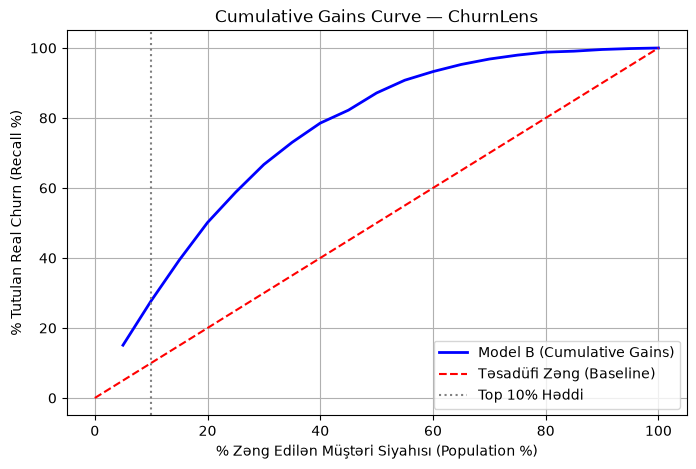


=== TAPŞIRIQ 5: BİZNES İQ TİSADİYYATI (TOP 10%) ===
Zəng Xərci (704 zəng x 10 AZN)   : 7,040.00 AZN
Xilas Edilən Məcmu CLV Dəyəri    : 416,898.00 AZN
Xalis Biznes Mənfəəti (Net ROI)  : 409,858.00 AZN


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

# ---------------------------------------------------------
# TAPŞIRIQ 1: Out-of-fold ehtimalların alınması
# ---------------------------------------------------------
df = pd.read_csv("../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].str.strip(), errors='coerce').fillna(0.0)

y = (df['Churn'] == 'Yes').astype(int)

num_features = ['tenure', 'MonthlyCharges']
cat_features = [
    'gender', 'Contract', 'PaymentMethod', 'PaperlessBilling',
    'InternetService', 'OnlineSecurity', 'OnlineBackup',
    'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies'
]

X_B = df[num_features + cat_features]

preprocessor_B = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), cat_features)
    ]
)

pipeline_B = Pipeline([
    ('preprocessor', preprocessor_B),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# cross_val_predict ilə HƏR müştərinin ehtimalı özünün OLMADIĞI (out-of-fold) kəsimdə hesablanır!
y_proba_oof = cross_val_predict(pipeline_B, X_B, y, cv=cv, method="predict_proba")[:, 1]

# ---------------------------------------------------------
# TAPŞIRIQ 2 & 3: Sıralama, Top 10% və Üç Göstərici
# ---------------------------------------------------------
df_results = pd.DataFrame({
    'y_true': y.values,
    'y_proba': y_proba_oof,
    'CLV_est': (df['MonthlyCharges'] * 12).values,
})
df_results = df_results.sort_values('y_proba', ascending=False).reset_index(drop=True)

N = len(df_results)
k_10 = int(0.10 * N)  # ~704 müştəri
total_churners = df_results['y_true'].sum()
base_churn_rate = df_results['y_true'].mean()

top_10_churners = df_results.iloc[:k_10]['y_true'].sum()

precision_10 = top_10_churners / k_10
recall_10 = top_10_churners / total_churners
lift_10 = precision_10 / base_churn_rate

print("=== TAPŞIRIQ 3: TOP 10% METRİKLƏRİ ===")
print(f"Zəng Edilən Müştəri Sayı (k) : {k_10}")
print(f"Tutulan Churn Sayı           : {top_10_churners} / {total_churners}")
print(f"Precision@10%               : {precision_10:.4f} ({precision_10*100:.2f}%-i real churn-dür)")
print(f"Recall@10%                  : {recall_10:.4f} (Ümumi churn-lərin {recall_10*100:.2f}%-i tutuldu)")
print(f"Lift@10%                    : {lift_10:.2f}x (Təsadüfdən {lift_10:.2f} dəfə güclüdür)")

# ---------------------------------------------------------
# TAPŞIRIQ 4: Cumulative Gains Curve (Qrafik)
# ---------------------------------------------------------
percentages = np.linspace(0.05, 1.0, 20)
recalls = []

for p in percentages:
    k = int(p * N)
    rec = df_results.iloc[:k]['y_true'].sum() / total_churners
    recalls.append(rec)

plt.figure(figsize=(8, 5))
plt.plot(percentages * 100, np.array(recalls) * 100, label='Model B (Cumulative Gains)', color='blue', lw=2)
plt.plot([0, 100], [0, 100], label='Təsadüfi Zəng (Baseline)', color='red', linestyle='--')
plt.axvline(x=10, color='gray', linestyle=':', label='Top 10% Həddi')
plt.xlabel('% Zəng Edilən Müştəri Siyahısı (Population %)')
plt.ylabel('% Tutulan Real Churn (Recall %)')
plt.title('Cumulative Gains Curve — ChurnLens')
plt.legend()
plt.grid(True)

import os
os.makedirs("../reports/figures", exist_ok=True)
plt.savefig("../reports/figures/telco_gains_curve.png", dpi=150, bbox_inches="tight")
plt.show()

# ---------------------------------------------------------# ---------------------------------------------------------
# Şərtlər:
# 1 Zəngin Xərci = 10 AZN
# CLV Təxmini = MonthlyCharges * 12 (İllik dəyər)
df['CLV_est'] = df['MonthlyCharges'] * 12
df_results['CLV_est'] = df['CLV_est'].iloc[df_results.index].values

cost_per_call = 10.0
total_call_cost = k_10 * cost_per_call

# Xilas edilən churn müştərilərin CLV gəliri (Tutulanların illik dəyəri)
saved_clv = df_results.iloc[:k_10][df_results.iloc[:k_10]['y_true'] == 1]['CLV_est'].sum()
net_profit = saved_clv - total_call_cost

print("\n=== TAPŞIRIQ 5: BİZNES İQ TİSADİYYATI (TOP 10%) ===")
print(f"Zəng Xərci (704 zəng x 10 AZN)   : {total_call_cost:,.2f} AZN")
print(f"Xilas Edilən Məcmu CLV Dəyəri    : {saved_clv:,.2f} AZN")
print(f"Xalis Biznes Mənfəəti (Net ROI)  : {net_profit:,.2f} AZN")

In [11]:
cost_per_call = 10.0
save_rate = 0.30   # nümunə: zəngdən sonra qalan churn-çülərin payı (sınaqla ölçülməlidir)
margin    = 0.50   # nümunə: gəlirin mənfəət payı

top = df_results.iloc[:k_10]
cost = k_10 * cost_per_call

model_caught_clv = top.loc[top.y_true == 1, 'CLV_est'].sum()
avg_clv_churn = df_results.loc[df_results.y_true == 1, 'CLV_est'].mean()
random_caught_clv = k_10 * base_churn_rate * avg_clv_churn

def net(caught_clv):
    return save_rate * margin * caught_clv - cost

print("Model net        :", round(net(model_caught_clv)))
print("Təsadüfi net     :", round(net(random_caught_clv)))
print("Modelin üstünlüyü:", round(net(model_caught_clv) - net(random_caught_clv)))

Model net        : 55495
Təsadüfi net     : 14930
Modelin üstünlüyü: 40565


In [12]:
margin = 0.50
for sr in [0.05, 0.10, 0.20, 0.30, 0.50]:
    m = sr * margin
    print(f"save_rate={sr:.2f} | Model: {m*model_caught_clv - cost:>10,.0f} | Təsadüfi: {m*random_caught_clv - cost:>10,.0f}")

print("Break-even (model):", round(cost / (margin * model_caught_clv), 4))
print("Break-even (təsadüfi):", round(cost / (margin * random_caught_clv), 4))

save_rate=0.05 | Model:      3,382 | Təsadüfi:     -3,378
save_rate=0.10 | Model:     13,805 | Təsadüfi:        283
save_rate=0.20 | Model:     34,650 | Təsadüfi:      7,606
save_rate=0.30 | Model:     55,495 | Təsadüfi:     14,930
save_rate=0.50 | Model:     97,184 | Təsadüfi:     29,576
Break-even (model): 0.0338
Break-even (təsadüfi): 0.0961


# ## Nəticələr (Faza 5)

**Out-of-fold ehtimallar.** Model B (`pipeline_B`) 5-fold stratified CV ilə qiymətləndirildi. Hər müştərinin ehtimalı ona baxmayan fold-da hesablandı (`cross_val_predict`), beləliklə nəticə öz cavabını görərək şişirilmir.

**Top 10% metrikləri.** Ehtimalla sıralanmış 7043 müştərinin ilk 704-ü (10%) zəng siyahısına alındı.

| Göstərici | Dəyər |
|---|---|
| Zəng edilən müştəri (k) | 704 |
| Tutulan churn | 519 / 1869 |
| Precision@10% | 0.737 |
| Recall@10% | 0.278 |
| Lift@10% | 2.78× |

Baza churn nisbəti 26.5%-dir, yəni təsadüfi zəngdə 704 müştərinin təxminən 187-si churn edərdi. Model 519 churn tapır, yəni təsadüfi seçimdən təxminən 332 çox.

**Biznes müqayisəsi.** Hesab üçün fərziyyələr: zəng xərci 10 AZN, CLV = `MonthlyCharges × 12` (illik gəlir), save rate 0.30 və mənfəət marjası 0.50 (nümunə dəyərlər, sınaqla ölçülməlidir).

- Model tutulan churn-lərin CLV cəmi: 530,653 AZN, təsadüfi gözləntisi: 166,887 AZN
- Model net nəticəsi: 72,558 AZN, təsadüfi: 17,993 AZN, fərq: 54,565 AZN
- CLV-cə nisbət: 3.18×, sayca nisbət: 2.78×

Model həm daha çox churn tutur, həm də orta churn müştərisinin CLV-si daha yüksəkdir (təxminən 1022 AZN, təsadüfidə 892 AZN). Yəni seçdiyi müştərilər daha dəyərlidir.

**Break-even.** Zəngin özünü ödəməsi üçün lazım olan save rate modeldə təxminən 2.7%, təsadüfi seçimdə təxminən 8.4%-dir. Model zəngi təsadüfi yanaşmadan üç dəfə aşağı save rate ilə gəlirli edir.

**Məhdudiyyətlər.**
- CLV illik gəlirdir, lifetime value deyil. Müddət, endirim və mənfəət marjası tam nəzərə alınmayıb.
- Save rate və margin fərziyyədir, yalnız A/B test ilə təsdiqlənə bilər. Mütləq AZN rəqəmləri bu fərziyyələrə həssasdır, nisbətlər isə yox.
- Model yüksək ödənişli müştərilərə üstünlük verir. Onların save rate-i fərqli ola bilər.
- Zəng xərci sabit 10 AZN kimi götürülüb, real xərc operator vaxtı və bonus payından ibarətdir.
- Telco datası snapshot-dır, zamana görə test (out-of-time) aparmaq mümkün deyil.